# FastText Word Embeddings on Yelp Tips

This notebook compares three embedding setups:

1. **Step 1 — Yelp FastText:** train FastText embeddings from the Yelp tips text.
2. **Step 2 — Pretrained FastText vectors:** load pretrained crawl vectors and inspect their nearest neighbors.
3. **Step 3 — Yelp-adapted vectors:** initialize Yelp vocabulary vectors from the pretrained vectors, then continue training on Yelp text.

The comparison focuses on nearest-neighbor words for a query such as `good`. Results depend on the dataset sample, pretrained-vector file, and training settings.

## 1. Setup and configuration



In [2]:
import os
import re
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gensim.models import FastText, KeyedVectors

RANDOM_SEED = 42
MAX_REVIEWS = 50_001
QUERY_WORD = "good"
VECTOR_SIZE = 300
WINDOW = 5
MIN_COUNT = 2
EPOCHS = 5
PRETRAINED_LIMIT = 200_000

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

print("Configuration loaded.")

Configuration loaded.


## 2. Locate and load Yelp text

The original project uses the `text` field from `yelp_academic_dataset_tip.json` and reads up to 50,001 records. Set `YELP_JSONL_PATH` if automatic discovery does not find the file.

In [3]:
YELP_JSONL_PATH = "/kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_tip.json"

def find_file(filename, search_roots=None):
    roots = search_roots or [Path("/kaggle/input"), Path("data"), Path(".")]
    for root in roots:
        root = Path(root)
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0]
    return None

if YELP_JSONL_PATH:
    yelp_path = Path(YELP_JSONL_PATH)
else:
    yelp_path = find_file("yelp_academic_dataset_tip.json")

if yelp_path is None or not yelp_path.exists():
    raise FileNotFoundError(
        "Could not find yelp_academic_dataset_tip.json. "
        "Set YELP_JSONL_PATH to the full dataset path."
    )

texts = []
with yelp_path.open("r", encoding="utf-8") as file:
    for line_number, line in enumerate(file):
        if line_number >= MAX_REVIEWS:
            break
        try:
            record = json.loads(line)
            text = record.get("text", "")
            if isinstance(text, str) and text.strip():
                texts.append(text)
        except json.JSONDecodeError:
            continue

print(f"Loaded {len(texts):,} text records from: {yelp_path}")
if not texts:
    raise ValueError("No usable text records were loaded.")

Loaded 50,001 text records from: /kaggle/input/datasets/yelp-dataset/yelp-dataset/yelp_academic_dataset_tip.json


## 3. Text preprocessing

The same preprocessing pipeline is used for all Yelp-trained models. It lowercases text, removes digits and punctuation, tokenizes alphabetic words, and removes English stopwords. Empty sentences are discarded.

In [4]:
import nltk
from nltk.corpus import stopwords

for resource in ("stopwords",):
    try:
        nltk.data.find(f"corpora/{resource}")
    except LookupError:
        nltk.download(resource, quiet=True)

STOP_WORDS = set(stopwords.words("english"))

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    tokens = re.findall(r"[a-z]+", text)
    return [token for token in tokens if token not in STOP_WORDS]

sentences = [preprocess_text(text) for text in texts]
sentences = [tokens for tokens in sentences if tokens]

if not sentences:
    raise ValueError("Preprocessing produced no non-empty sentences.")

token_count = sum(map(len, sentences))
vocabulary_preview = sorted({word for sent in sentences for word in sent})[:20]
print(f"Sentences: {len(sentences):,}")
print(f"Tokens: {token_count:,}")
print("Vocabulary sample:", vocabulary_preview)

Sentences: 49,908
Tokens: 326,138
Vocabulary sample: ['aa', 'aaa', 'aaaaamazing', 'aaaah', 'aaaamazing', 'aaamazing', 'aaas', 'aac', 'aadvantange', 'aah', 'aahhhh', 'aahhhhhh', 'aaron', 'aau', 'ab', 'abalone', 'abandoned', 'abarita', 'abba', 'abbey']


## 4. Step 1 — Train FastText on Yelp

FastText represents a word using character n-gram information in addition to the whole-word representation. This can help it form useful representations for rare or unseen word forms.

In [5]:
yelp_model = FastText(
    sentences=sentences,
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=max(1, (os.cpu_count() or 2) - 1),
    sg=1,
    seed=RANDOM_SEED,
    epochs=EPOCHS
)

yelp_model.save(str(OUTPUT_DIR / "fasttext_yelp.model"))
print("Yelp FastText model trained and saved.")

Yelp FastText model trained and saved.


### Inspect Step 1

In [6]:
def show_similar(model_or_vectors, word, topn=10):
    if word not in model_or_vectors:
        print(f"'{word}' is not in this model's vocabulary.")
        return []
    results = model_or_vectors.most_similar(word, topn=topn)
    for term, score in results:
        print(f"{term:<25} {score:.4f}")
    return results

print(f"Nearest neighbors for '{QUERY_WORD}' — Step 1")
step1_neighbors = show_similar(yelp_model.wv, QUERY_WORD)

Nearest neighbors for 'good' — Step 1
goood                     0.9487
gooood                    0.9358
mood                      0.9155
goodbye                   0.9151
gooooood                  0.9149
enjoyed                   0.9143
goods                     0.9111
solid                     0.9090
tasty                     0.9066
gooooooood                0.9019


## 5. Step 2 — Load pretrained FastText vectors

Download or attach the pretrained `crawl-300d-2M.vec` file separately. This text-format vector file can be very large. The `limit` parameter controls how many entries are loaded into memory.

In [7]:
PRETRAINED_VECTOR_PATH = "/kaggle/input/datasets/yekenot/fasttext-crawl-300d-2m/crawl-300d-2M.vec"
if PRETRAINED_VECTOR_PATH:
    pretrained_path = Path(PRETRAINED_VECTOR_PATH)
else:
    pretrained_path = find_file("crawl-300d-2M.vec")

if pretrained_path is None or not pretrained_path.exists():
    raise FileNotFoundError(
        "Could not find crawl-300d-2M.vec. Attach/download the pretrained vectors "
        "and set PRETRAINED_VECTOR_PATH to the file location."
    )

pretrained_vectors = KeyedVectors.load_word2vec_format(
    str(pretrained_path),
    binary=False,
    limit=PRETRAINED_LIMIT
)
print(f"Loaded {len(pretrained_vectors):,} pretrained vectors.")

Loaded 200,000 pretrained vectors.


### Inspect Step 2

In [8]:
print(f"Nearest neighbors for '{QUERY_WORD}' — Step 2")
step2_neighbors = show_similar(pretrained_vectors, QUERY_WORD)

Nearest neighbors for 'good' — Step 2
great                     0.7415
bad                       0.7370
decent                    0.6838
goood                     0.6778
Good                      0.6698
nice                      0.6627
excellent                 0.6599
not-so-good               0.6422
agood                     0.6234
gooood                    0.6042


## 6. Step 3 — Adapt pretrained vectors to Yelp

A FastText model is initialized with the Yelp vocabulary. Matching vectors are copied from the pretrained vector file, then the model is trained on Yelp sentences so the representations can adapt to the Yelp domain.

Only words present in both vocabularies can receive pretrained initial vectors. FastText's subword parameters are still learned by the Yelp training process.

In [9]:
adapted_model = FastText(
    vector_size=VECTOR_SIZE,
    window=WINDOW,
    min_count=MIN_COUNT,
    workers=max(1, (os.cpu_count() or 2) - 1),
    sg=1,
    seed=RANDOM_SEED
)
adapted_model.build_vocab(corpus_iterable=sentences)

# Allow matched vectors to be updated during subsequent training.
adapted_model.wv.vectors_lockf = np.ones(len(adapted_model.wv), dtype=np.float32)

adapted_model.wv.intersect_word2vec_format(
    str(pretrained_path),
    binary=False,
    lockf=1.0
)

adapted_model.train(
    corpus_iterable=sentences,
    total_examples=len(sentences),
    epochs=EPOCHS
)

adapted_model.save(str(OUTPUT_DIR / "fasttext_yelp_adapted.model"))
print("Yelp-adapted FastText model trained and saved.")

Yelp-adapted FastText model trained and saved.


### Inspect Step 3

In [10]:
print(f"Nearest neighbors for '{QUERY_WORD}' — Step 3")
step3_neighbors = show_similar(adapted_model.wv, QUERY_WORD)

Nearest neighbors for 'good' — Step 3
goood                     0.9549
gooood                    0.9426
mood                      0.9211
gooooood                  0.9185
enjoyed                   0.9157
goods                     0.9137
goodbye                   0.9112
solid                     0.9109
tasty                     0.9094
gooooooood                0.9037


## 7. Compare nearest neighbors

The table below contains the top similar words and cosine similarity scores for each setup. Similarity scores are meaningful within each embedding space; compare the qualitative neighbors as well as the numeric values.

In [11]:
def collect_neighbors(vectors, query_word, step_name, topn=10):
    if query_word not in vectors:
        return pd.DataFrame(columns=["Step", "Query", "Rank", "Neighbor", "Cosine Similarity"])
    rows = []
    for rank, (neighbor, score) in enumerate(vectors.most_similar(query_word, topn=topn), start=1):
        rows.append({
            "Step": step_name,
            "Query": query_word,
            "Rank": rank,
            "Neighbor": neighbor,
            "Cosine Similarity": float(score)
        })
    return pd.DataFrame(rows)

comparison_df = pd.concat([
    collect_neighbors(yelp_model.wv, QUERY_WORD, "Step 1: Yelp FastText"),
    collect_neighbors(pretrained_vectors, QUERY_WORD, "Step 2: Pretrained FastText"),
    collect_neighbors(adapted_model.wv, QUERY_WORD, "Step 3: Yelp-adapted FastText")
], ignore_index=True)

display(comparison_df)
comparison_df.to_csv(OUTPUT_DIR / "nearest_neighbors_comparison.csv", index=False)

,Step,Query,Rank,Neighbor,Cosine Similarity
0,Step 1: Yelp FastText,good,1,goood,0.948674
1,Step 1: Yelp FastText,good,2,gooood,0.935809
2,Step 1: Yelp FastText,good,3,mood,0.915454
3,Step 1: Yelp FastText,good,4,goodbye,0.915054
4,Step 1: Yelp FastText,good,5,gooooood,0.914860
5,Step 1: Yelp FastText,good,6,enjoyed,0.914292
6,Step 1: Yelp FastText,good,7,goods,0.911051
7,Step 1: Yelp FastText,good,8,solid,0.908979
8,Step 1: Yelp FastText,good,9,tasty,0.906637
9,Step 1: Yelp FastText,good,10,gooooooood,0.901931


## 8. Visualize average nearest-neighbor similarity

This plot summarizes the mean cosine similarity of the top neighbors for each model. It is a descriptive statistic, not a standalone measure of embedding quality.

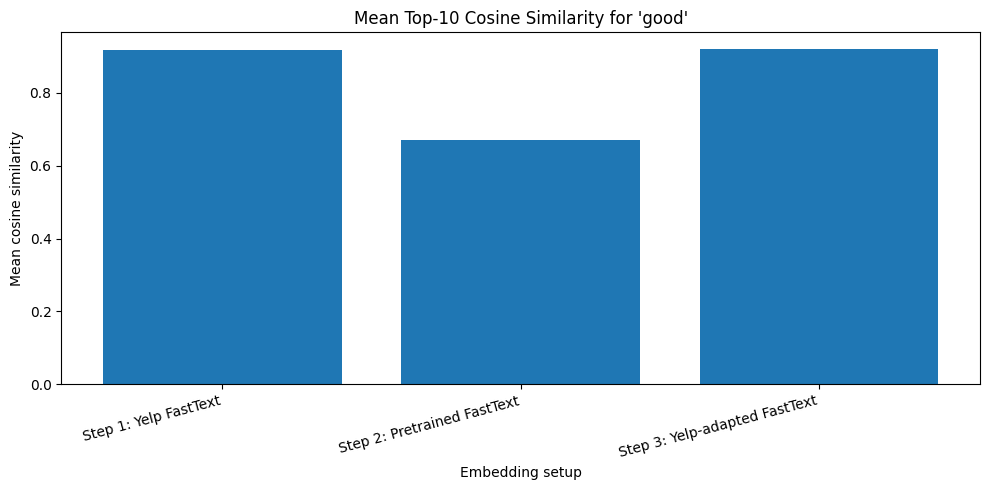

In [12]:
if not comparison_df.empty:
    mean_scores = (
        comparison_df.groupby("Step", as_index=False)["Cosine Similarity"]
        .mean()
    )
    plt.figure(figsize=(10, 5))
    plt.bar(mean_scores["Step"], mean_scores["Cosine Similarity"])
    plt.title(f"Mean Top-10 Cosine Similarity for '{QUERY_WORD}'")
    plt.xlabel("Embedding setup")
    plt.ylabel("Mean cosine similarity")
    plt.xticks(rotation=15, ha="right")
    plt.tight_layout()
    plt.show()
    mean_scores.to_csv(OUTPUT_DIR / "mean_similarity_comparison.csv", index=False)

## 9. Opposite-direction neighbors — interpretation warning

The original notebook used `most_similar(positive=[word], negative=...)` / the negated vector to retrieve words in an opposite vector direction. These are **not guaranteed antonyms**. Distributional embeddings encode contextual similarity and association, not a reliable dictionary of opposites. Therefore, this notebook focuses its main comparison on nearest neighbors and does not label opposite-direction results as antonyms.

In [13]:
def opposite_direction_neighbors(vectors, word, topn=10):
    if word not in vectors:
        raise KeyError(f"'{word}' is not available in this vocabulary.")
    return vectors.similar_by_vector(-vectors[word], topn=topn)

if QUERY_WORD in yelp_model.wv:
    opposite_direction = opposite_direction_neighbors(yelp_model.wv, QUERY_WORD)
    print("Opposite-direction neighbors (not necessarily antonyms):")
    for term, score in opposite_direction:
        print(f"{term:<25} {score:.4f}")

Opposite-direction neighbors (not necessarily antonyms):
wpo                       -0.3201
card                      -0.4268
http                      -0.4333
th                        -0.4365
per                       -0.4431
haiku                     -0.4432
www                       -0.4492
cards                     -0.4499
com                       -0.4520
credit                    -0.4529


## 10. Save experiment summary

The summary records the configuration and corpus size so the experiment can be interpreted and reproduced.

In [14]:
summary = pd.DataFrame([{
    "dataset_file": str(yelp_path),
    "number_of_text_records": len(texts),
    "number_of_nonempty_sentences": len(sentences),
    "token_count_after_preprocessing": token_count,
    "query_word": QUERY_WORD,
    "vector_size": VECTOR_SIZE,
    "window": WINDOW,
    "min_count": MIN_COUNT,
    "epochs": EPOCHS,
    "pretrained_vector_file": str(pretrained_path),
    "pretrained_limit": PRETRAINED_LIMIT
}])
summary.to_csv(OUTPUT_DIR / "experiment_summary.csv", index=False)

print("Saved outputs to:", OUTPUT_DIR.resolve())
print("Files:", sorted(p.name for p in OUTPUT_DIR.iterdir()))

Saved outputs to: /kaggle/working/outputs
Files: ['experiment_summary.csv', 'fasttext_yelp.model', 'fasttext_yelp.model.wv.vectors_ngrams.npy', 'fasttext_yelp_adapted.model', 'fasttext_yelp_adapted.model.wv.vectors_ngrams.npy', 'mean_similarity_comparison.csv', 'nearest_neighbors_comparison.csv']


## Notes and limitations

- The Yelp input is the Yelp tips JSONL file (`yelp_academic_dataset_tip.json`), matching the source notebook.
- The pretrained crawl vectors are a separate, large download and are not bundled in this repository.
- Loading only the first `PRETRAINED_LIMIT` entries is a memory-saving choice; it may affect whether a queried word is available.
- The original project compares three embedding setups. The pretrained-only model and Yelp-trained models use different corpora, so their neighborhoods can differ for several reasons.
- Nearest neighbors are not a sentiment classifier and do not directly measure downstream task performance.